I made this notebook a while a go as a mean to learn how plotting in matplotlib works. I dont think it's really usefull unless for sanity checking of my logic etc.

In [ ]:
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, PathPatch
from matplotlib.path import Path

## 1 plot axes etc

Axes = (x, y).
`(0, 0)` is bottom left
`(1, 1)` top-right.

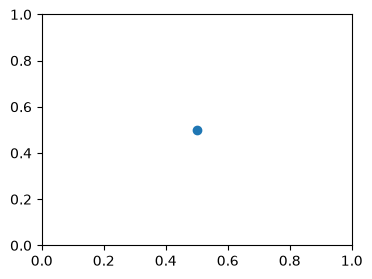

In [ ]:
fig_pt_1, dot_1 = plt.subplots(figsize=(4, 3))
dot_1.plot(0.5, 0.5, "o")
dot_1.set_xlim(0, 1)
dot_1.set_ylim(0, 1)
fig_pt_1

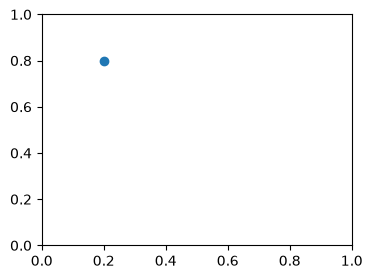

In [ ]:
fig_pt_2, dot_2 = plt.subplots(figsize=(4, 3))
dot_2.plot(0.2, 0.8, "o")
dot_2.set_xlim(0, 1)
dot_2.set_ylim(0, 1)
fig_pt_2

## 2 Chromosome

Chr is rectangle:
`Rectangle((x, y), width, height)` - `(x, y)` is bottom left corner and `ax.add_patch(...)` puts it on the grid. That grey bar is a chromosome.

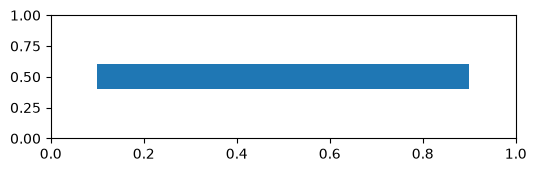

In [ ]:
fig_bar, chr = plt.subplots(figsize=(6, 1.6))
chr.add_patch(Rectangle((0.1, 0.4), 0.8, 0.2))
chr.set_xlim(0, 1)
chr.set_ylim(0, 1)
fig_bar

## 3 two chr

Put one bar/chr high, one chr low. Diff widths mean diff genome lengths.

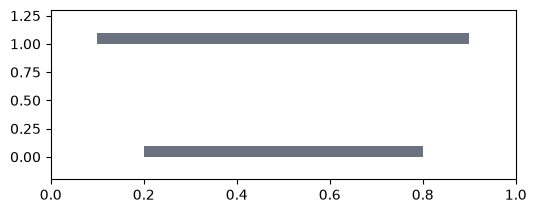

In [ ]:
fig_rows, ax_rows = plt.subplots(figsize=(6, 2.2))
ax_rows.add_patch(Rectangle((0.1, 1.0), 0.8, 0.1, facecolor="#6b7280")) # this for Chr 1, color grey bc it looks better
ax_rows.add_patch(Rectangle((0.2, 0.0), 0.6, 0.1, facecolor="#6b7280")) # this is chr 2
ax_rows.set_xlim(0, 1)
ax_rows.set_ylim(-0.2, 1.3)
fig_rows

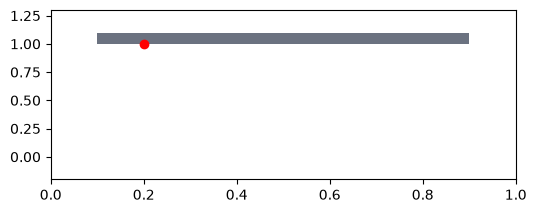

In [ ]:
fig_rows1, ax_rows1 = plt.subplots(figsize=(6, 2.2))
ax_rows1.add_patch(Rectangle((0.1, 1.0), 0.8, 0.1, facecolor="#6b7280")) # this for Chr 1
ax_rows1.plot(0.2, 1.0, "o", color = "red") # this makes a dot on chr, this is how we will represent a gene/locus, basically a dot on chr. 
ax_rows1.set_xlim(0, 1)
ax_rows1.set_ylim(-0.2, 1.3)
fig_rows1

## 4 coordinates handling

Now it becomes more complex as real gene positions are given in bp (or kb,mb etc.) and we would need to introduce some conversion from bp to x,y (mainly x, as y is linked to chr).

The way how I decided to handle it is to have a `scale` factor which is being calculated as `scale = 1 / genome_size`, then `x = pos * scale`.

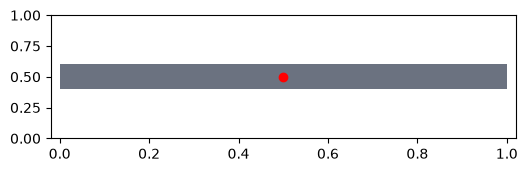

In [ ]:
Chr_size = 10_000_000
scale = 1.0 / Chr_size

pos = 5_000_000
locus_x = pos * scale

fig_sc, ax_sc = plt.subplots(figsize=(6, 1.6))
ax_sc.add_patch(Rectangle((0, 0.4), Chr_size * scale, 0.2, facecolor="#6b7280"))
ax_sc.plot(locus_x, 0.5, "o", color="red")
ax_sc.set_xlim(-0.02, 1.02)
ax_sc.set_ylim(0, 1)
fig_sc

# In this example if you'll set pos to 5 Mb you'll get x = 0.5, which is exactly middle of our chr etc. 

We reuse these below: a ribbon starts at `y_top` (bottom edge of the upper chr), ends at `y_bot` (top edge of lower chr), and `y_mid` is halfway.

In [ ]:
y_top, y_bot = 1.0, 0.1
y_mid = (y_top + y_bot) / 2

## 5 connect two loci with a line

using `y_top` and `y_bot` we can print two loci and then connect them with a line, thikness of a line is set-up with `lw`.

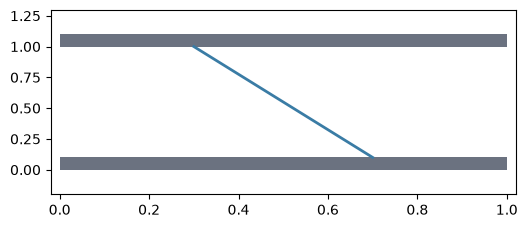

In [ ]:
fig_ln, ax_ln = plt.subplots(figsize=(6, 2.4))
ax_ln.add_patch(Rectangle((0, y_top), 1.0, 0.1, facecolor="#6b7280"))
ax_ln.add_patch(Rectangle((0, 0.0), 1.0, 0.1, facecolor="#6b7280"))
ax_ln.plot([0.3, 0.7], [y_top, y_bot], color="#3a7ca5", lw=2) # in [0.3, 0.7] change x (0.3) to move position on chr1 and y (0.7) to move it in chr2.
ax_ln.set_xlim(-0.02, 1.02)
ax_ln.set_ylim(-0.2, 1.3)
fig_ln

Lastly its better to get rid of those axis for clear image, hence `ax_cv.axis("off")`

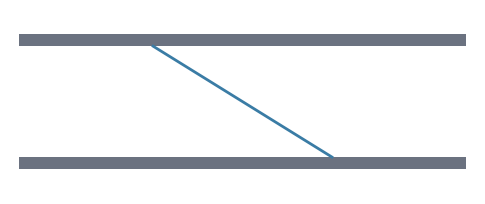

In [ ]:
fig_ln1, ax_ln1 = plt.subplots(figsize=(6, 2.4))
ax_ln1.add_patch(Rectangle((0, 1), 1.0, 0.1, facecolor="#6b7280"))
ax_ln1.add_patch(Rectangle((0, 0.0), 1.0, 0.1, facecolor="#6b7280"))
ax_ln1.plot([0.3, 0.7], [1, 0.1], color="#3a7ca5", lw=2) # in [0.3, 0.7] change x (0.3) to move position on chr1 and y (0.7) to move it in chr2.
ax_ln1.set_xlim(-0.02, 1.02)
ax_ln1.set_ylim(-0.2, 1.3)
ax_ln1.axis("off")
fig_ln1

## 6 Nicer curves

This part is purely cosmetics, but its the hardest part here. We are using CURVE4 and it needs 4 points, start, two control points and
an end.

The curve bends toward the control points. Therefore both control points must be on the midline (here grey dots on plot).

This makes S-shape.

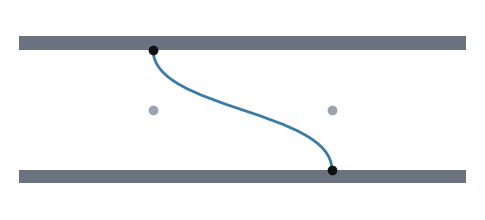

In [ ]:
xa, xb = 0.3, 0.7
verts_cv = [(xa, y_top), (xa, y_mid), (xb, y_mid), (xb, y_bot)]
codes_cv = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4]

fig_cv, ax_cv = plt.subplots(figsize=(6, 2.6))
ax_cv.add_patch(Rectangle((0, y_top), 1.0, 0.1, facecolor="#6b7280"))
ax_cv.add_patch(Rectangle((0, 0.0), 1.0, 0.1, facecolor="#6b7280"))
ax_cv.add_patch(PathPatch(Path(verts_cv, codes_cv), fill=False, edgecolor="#3a7ca5", lw=2))
ax_cv.plot([xa, xb], [y_mid, y_mid], "o", color="#9ca3af")
ax_cv.plot([xa, xb], [y_top, y_bot], "o", color="#111111")
ax_cv.set_xlim(-0.02, 1.02)
ax_cv.set_ylim(-0.2, 1.3)
ax_cv.axis("off")
fig_cv

## 7 make a proper ribbon

A ribbon is just two of those curves closed from all sides (down the left edge, across bottom, up right edge and close across the top). This is done with `[xa1, xa2]` on top and `[xb1, xb2]` below.

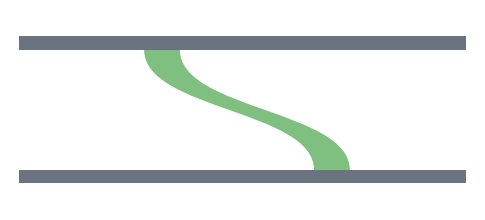

In [ ]:
ft1, ft2 = 0.28, 0.36
fb1, fb2 = 0.66, 0.74
verts_rb = [(ft1, y_top), (ft1, y_mid), (fb1, y_mid), (fb1, y_bot), (fb2, y_bot), (fb2, y_mid), (ft2, y_mid), (ft2, y_top), (ft1, y_top)]
codes_rb = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]

fig_rb, ax_rb = plt.subplots(figsize=(6, 2.6))
ax_rb.add_patch(Rectangle((0, y_top), 1.0, 0.1, facecolor="#6b7280"))
ax_rb.add_patch(Rectangle((0, 0.0), 1.0, 0.1, facecolor="#6b7280"))
ax_rb.add_patch(PathPatch(Path(verts_rb, codes_rb), facecolor="green", alpha=0.5, edgecolor="none"))
ax_rb.set_xlim(-0.02, 1.02)
ax_rb.set_ylim(-0.2, 1.3)
ax_rb.axis("off")
fig_rb

## 8 making function

Now all that code can go in `function` that we will re-use with some modificaitons.

In [ ]:
def make_ribbon(top_chr_span, bot_chr_span, y_top, y_bot, color):
    xa1, xa2 = top_chr_span
    xb1, xb2 = bot_chr_span
    ym = (y_top + y_bot) / 2
    verts = [(xa1, y_top), (xa1, ym), (xb1, ym), (xb1, y_bot), (xb2, y_bot), (xb2, ym), (xa2, ym), (xa2, y_top), (xa1, y_top)]
    codes = [Path.MOVETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.LINETO, Path.CURVE4, Path.CURVE4, Path.CURVE4, Path.CLOSEPOLY]
    return PathPatch(Path(verts, codes), facecolor=color, alpha=0.5, edgecolor="none")

def foot(p, scale, half=0.012):
    x = p * scale
    return (x - half, x + half)

Now we can add more links and plot

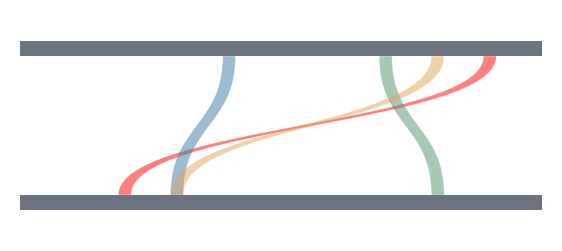

In [ ]:
links = [(9_000_000, 2_000_000, "red"),
         (4_000_000, 3_000_000, "#3a7ca5"),
         (7_000_000, 8_000_000, "#4c956c"),
         (8_000_000, 3_000_000, "#e0a458")]

fig_mini, ax_mini = plt.subplots(figsize=(7, 3))
ax_mini.add_patch(Rectangle((0, y_top), 1.0, 0.1, facecolor="#6b7280"))
ax_mini.add_patch(Rectangle((0, 0.0), 1.0, 0.1, facecolor="#6b7280"))
for p_top, p_bot, col in links:
    ax_mini.add_patch(make_ribbon(foot(p_top, scale), foot(p_bot, scale), y_top, y_bot, col))
ax_mini.set_xlim(-0.02, 1.02)
ax_mini.set_ylim(-0.2, 1.3)
ax_mini.axis("off")
fig_mini

## 9 this *is* synViser

Basically this functional is implemented in the main function called `ribbon_patch` in
`functions.py` (or whatever the name will be once it will end up on github).

The real engine only adds the coordinate bookkeeping (`x_offset`, `bp_before`, clamped feet) so many chromosomes of different sizes line up.